# Why a threshold calibrated on the poke run degrades the long, shaky run

**The question.** The threshold is calibrated on the poke run `poke_test_oct` (3 s at 30 fps, 22 labelled recordings, 14 mites). The long run `test_run_2026-09-08_Mathis_last_dsRNA` (295 recordings of 10 frames, 59 mites, 49 h, plates that shake) is the guide for shaky recordings. At the poke run's threshold the long run's calls get far worse. Is the shake the cause, and is there a fix?

**The data.** `scripts/shaky_recordings.py` read every labelled mite in every recording of both runs from the saved ROI videos and kept `results/scripts/shaky_recordings.csv.gz` (one row per mite and recording) plus each row's 64-direction outline profile (`shaky_recordings_profiles.npz`). This notebook only reads those two files and, in section 3, a few ROI videos. Each row holds:

- `own_centre`: the score as the app computes it (outline_variability, stabilized by the mite's own centre, divided by the noise floor). `none`, `plate_centre` and `plate_ecc` are the same score cut without stabilization, with the plate's median centre shift, and with the plate's ECC shift.
- `shake`: how far the plate moved within the recording, in pixels. This is the largest distance from the first frame of the plate's shift (the median over the mites of their centre shifts). `jitter` is the median step of that shift from one frame to the next.
- For the poke run, `short_*`: the same values with the recording cut to the long run's length (10 frames, every second one).

**A caveat on the long run's labels** (CLAUDE.md): they agree with this score at about 0.135 in all but a handful of recordings. Calls at 0.135 therefore match them almost by construction. That does not make 0.135 right. The question here is what goes wrong below 0.135, and section 3 checks that from the pixels, not from the labels.

```
python scripts/shaky_recordings.py --poke-root %TEMP%/zzrc/gt   # about 3 min; the poke run sits one folder too deep in recordings/
```

In [1]:
import os, sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.environ.setdefault("DISCOBOX_CONFIG", str(ROOT / "config.default.yaml"))  # the defaults, only read
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "scripts"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.ndimage import median_filter

from classes.ground_truth import calibration
from classes.results.survival import death_after
from shaky_recordings import OUT, PROFILES, LONG_RUN, POKE_RUN

%matplotlib inline
pd.set_option("display.precision", 3)
pd.set_option("display.width", 180)

table = pd.read_csv(OUT, dtype={"mite": str})
profiles = np.load(PROFILES)["profile"]
labelled = table["labelled"].to_numpy()
long_rows = labelled & (table["dataset"] == LONG_RUN).to_numpy()
poke_rows = labelled & (table["dataset"] == POKE_RUN).to_numpy()
long_run, poke = table[long_rows], table[poke_rows]
pd.DataFrame({name: {"mites": part["mite"].nunique(), "recordings": part["recording"].nunique(),
                     "frames per recording": int(part["frames"].median()),
                     "labelled moving": int(part["moving"].sum()), "labelled still": int((~part["moving"]).sum())}
              for name, part in (("long run", long_run), ("poke run", poke))}).T

,mites,recordings,frames per recording,labelled moving,labelled still
long run,59,295,10,843,16471
poke run,14,22,90,204,100


## 1. The symptom

Each threshold is applied to every labelled recording of the long run. The thresholds are:

- **best F1 on the poke run**: what the calibration report suggested on the morning of 26 October 2026.
- **best F0.5 on the poke run**: what it suggests since, after this notebook (`calibration.best_f05_threshold()`; section 6).
- **Youden's J on the poke run**: `calibration.best_threshold()`.
- **0.088**: the report's earlier suggestion, the threshold with the smallest death-time error on the poke run.
- **0.135**: the long run's own threshold.

A mite's death is `survival.death_after()`, the recording after its last call of moving, compared with the death that its labels give.

In [2]:
SCORE = "own_centre"


def death_offsets(part, score, threshold, rule=death_after, truth_rule=None):
    # Per mite: the death by the calls minus the death by the labels, in recordings.
    # truth_rule defaults to rule, so a rule is judged against itself on the labels.
    truth_rule = truth_rule or rule
    part = part.assign(_s=np.asarray(score)).sort_values(["mite", "recording"])
    return np.array([rule(list(g["_s"] >= threshold)) - truth_rule(list(g["moving"])) for _, g in part.groupby("mite")])


def judged(part, score, threshold, rule=death_after):
    called = np.asarray(score) >= threshold
    off = death_offsets(part, score, threshold, rule)
    return {"threshold": threshold,
            "still called moving": int((called & ~part["moving"].to_numpy()).sum()),
            "moving called still": int((~called & part["moving"].to_numpy()).sum()),
            "deaths exact": f"{(off == 0).sum()} / {len(off)}", "deaths late": int((off > 0).sum()),
            "mean death error (recordings)": float(np.abs(off).mean()), "worst (recordings)": int(np.abs(off).max())}


def best_f_threshold(scores, moving, beta):
    # the threshold with the largest F-beta, the highest of equal ones, halfway into the gap below (as the report places it)
    scores, moving = np.asarray(scores, dtype=float), np.asarray(moving, dtype=bool)
    candidates = np.unique(scores)[::-1]
    tp = np.array([(scores[moving] >= th).sum() for th in candidates])
    fp = np.array([(scores[~moving] >= th).sum() for th in candidates])
    f = calibration.f_score(tp, fp, moving.sum() - tp, beta)
    return calibration._into_gap(scores, candidates[int(np.argmax(f))])


THRESHOLDS = {"best F1 on the poke run": best_f_threshold(poke[SCORE], poke["moving"], 1.0),
              "best F0.5 on the poke run (in use)": calibration.best_f05_threshold(poke[SCORE], poke["moving"]),
              "Youden's J on the poke run": calibration.best_threshold(poke[SCORE], poke["moving"]),
              "0.088 (smallest death error on the poke run)": 0.088,
              "0.135 (the long run's own)": 0.135}
pd.DataFrame({name: judged(long_run, long_run[SCORE], th) for name, th in THRESHOLDS.items()}).T

,threshold,still called moving,moving called still,deaths exact,deaths late,mean death error (recordings),worst (recordings)
best F1 on the poke run,0.046,461,0,14 / 59,45,92.898,262
best F0.5 on the poke run (in use),0.087,74,1,49 / 59,10,5.881,149
Youden's J on the poke run,0.087,74,1,49 / 59,10,5.881,149
0.088 (smallest death error on the poke run),0.088,71,1,49 / 59,10,5.881,149
0.135 (the long run's own),0.135,5,6,57 / 59,1,0.847,46


**The long run degrades at the best-F1 threshold.** At about 0.046 (0.049 in the report, whose scores are rounded and cut where each mite was found) about 460 still recordings are called moving. Most mites then die late, on average by about 90 recordings (15 h). At Youden's J or 0.088 the damage is much smaller but still real: about 70 still recordings are called moving, and 10 deaths come late. The rest of this notebook looks for where those calls come from.

## 2. Is it the shake?

The long run shakes about five times more than the poke run. The shake also grows over the run: from recording ~120 on, the plate moves 0.15–0.24 px within a recording.

,50%,90%,max
dataset,,,
poke_test_oct,0.019,0.029,0.033
test_run_2026-09-08_Mathis_last_dsRNA,0.105,0.197,0.241


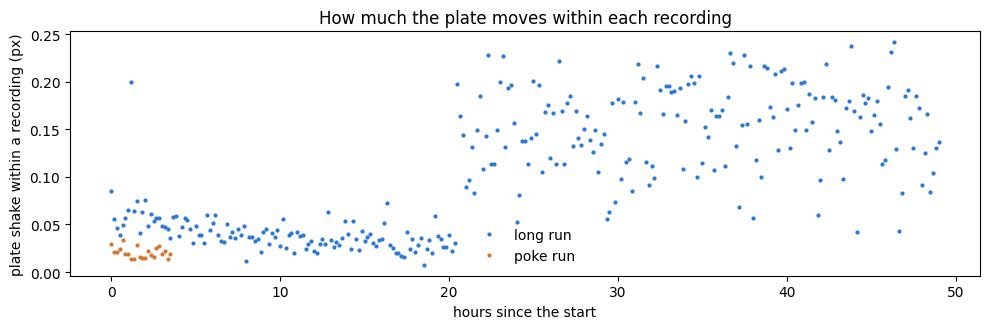

In [3]:
per_recording = table[labelled].groupby(["dataset", "recording"])[["shake", "jitter", "minutes"]].first().reset_index()
fig, ax = plt.subplots(figsize=(10, 3.4))
for name, colour in ((LONG_RUN, "#2a78d6"), (POKE_RUN, "#d6762a")):
    part = per_recording[per_recording["dataset"] == name]
    ax.plot(part["minutes"] / 60, part["shake"], ".", ms=4, color=colour, label="long run" if name == LONG_RUN else "poke run")
ax.set(xlabel="hours since the start", ylabel="plate shake within a recording (px)", title="How much the plate moves within each recording")
ax.legend(frameon=False)
plt.tight_layout()
per_recording.groupby("dataset")["shake"].describe(percentiles=[0.5, 0.9])[["50%", "90%", "max"]]

If the shake caused the wrong calls, they would sit in the shaky recordings. The table splits the long run's still recordings by shake and counts those called moving at Youden's threshold. It does so for the app's stabilization (`own_centre`), for the alternatives, and with no stabilization at all.

In [4]:
YOUDEN = THRESHOLDS["Youden's J on the poke run"]
still = long_run[~long_run["moving"]].copy()
still["shake (px)"] = pd.cut(still["shake"], [0, 0.05, 0.1, 0.15, 0.2, 0.25])
by_shake = still.groupby("shake (px)", observed=True).agg(
    recordings=("own_centre", "size"),
    **{f"{m} called moving": (m, lambda s: int((s >= YOUDEN).sum())) for m in ("none", "own_centre", "plate_centre", "plate_ecc")},
    **{"median score": ("own_centre", "median"), "99% of the scores": ("own_centre", lambda s: s.quantile(0.99))})
by_shake.loc["all"] = by_shake.sum(numeric_only=True)
by_shake.loc["all", ["median score", "99% of the scores"]] = [still["own_centre"].median(), still["own_centre"].quantile(0.99)]
by_shake

,recordings,none called moving,own_centre called moving,plate_centre called moving,plate_ecc called moving,median score,99% of the scores
shake (px),,,,,,,
"(0.0, 0.05]",5144.0,55.0,55.0,56.0,56.0,0.015,0.090
"(0.05, 0.1]",2541.0,17.0,14.0,16.0,16.0,0.015,0.071
"(0.1, 0.15]",3225.0,51.0,3.0,3.0,3.0,0.016,0.052
"(0.15, 0.2]",4212.0,121.0,2.0,2.0,2.0,0.017,0.058
"(0.2, 0.25]",1349.0,37.0,0.0,0.0,2.0,0.018,0.059
all,16471.0,281.0,74.0,77.0,79.0,0.016,0.063


**It is not the shake.** Without stabilization (`none`) the still mites of the shaky part are called moving several times more often. With the app's stabilization almost none are: the wrong calls sit in the *least* shaky recordings (below 0.05 px), early in the run. A still mite's median score and 99th percentile do not rise with the shake. The three ways of stabilizing are within a few calls of each other, so the per-mite centre (the user's choice of 2026-10-16) holds up on this run too.

The moving mites are also unharmed. At Youden's threshold one moving recording is called still (section 1). It does not matter whether the recording shakes.

## 3. What the wrong calls are

Most of the still recordings called moving at 0.088 fall while the mite is still alive: before its last labelled movement. Those calls do not change its death. The ones that matter come *after* the last labelled movement, because each of them brings a dead mite back to life. Below, each of those recordings is shown three ways: the mean of its frames (top), each pixel's standard deviation over the frames (middle, same scale for all), and the last frame minus the first (bottom).

71 still recordings called moving at 0.088; 13 after the mite's last labelled movement


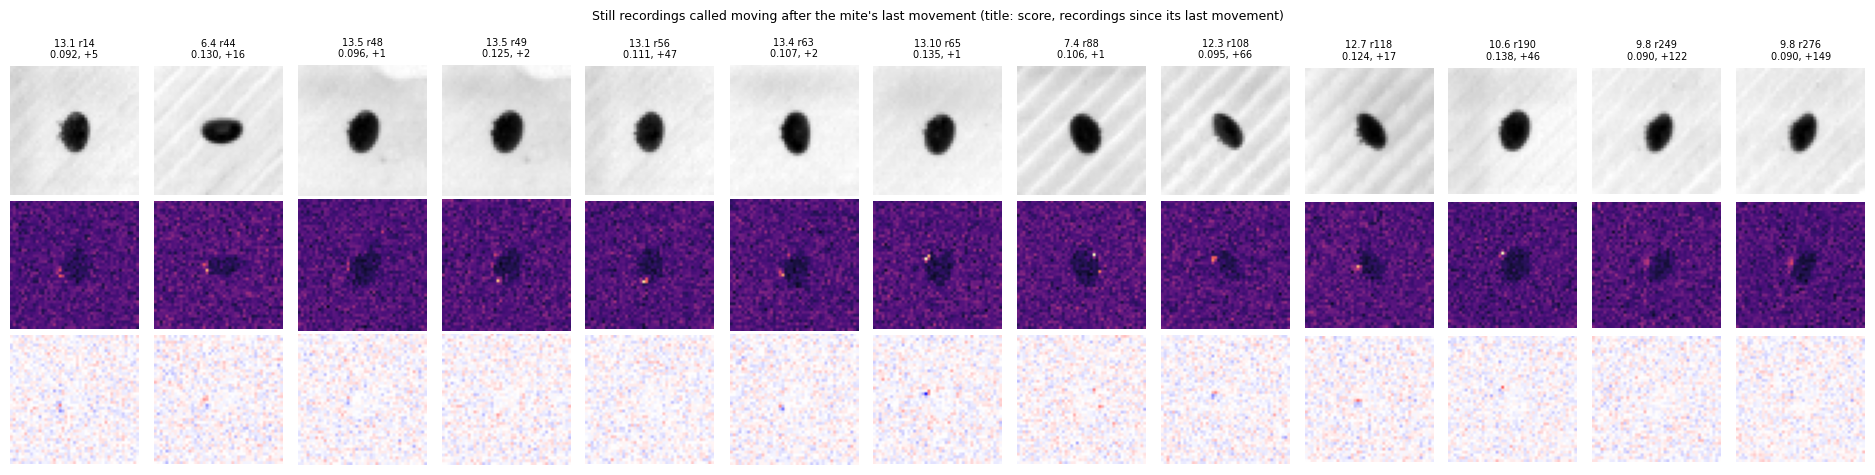

In [5]:
from classes.scoring.plate_stabilizer import PlateStabilizer
from centre_stabilization import centre_shifts
import shaky_recordings

last_moving = long_run[long_run["moving"]].groupby("mite")["recording"].max()
wrong = long_run[(long_run[SCORE] >= 0.088) & ~long_run["moving"]]
after_death = wrong[wrong["recording"] > wrong["mite"].map(last_moving)]
print(f"{len(wrong)} still recordings called moving at 0.088; {len(after_death)} after the mite's last labelled movement")

dataset, loader, mites, _labels = shaky_recordings._dataset(LONG_RUN, shaky_recordings.pipeline.RECORDINGS_ROOT)
number_of = dict(mites)


def stabilized(mite, recording):
    name = dataset["recordings"][recording]["name"]
    frames = loader.read_mite(name, number_of[mite]).astype(np.float32)
    box = shaky_recordings._box_in_roi(loader, name, number_of[mite])
    return PlateStabilizer.cut(frames, box, 16, centre_shifts(frames, box))[..., 0]


cuts = {(r.mite, r.recording): stabilized(r.mite, r.recording) for r in after_death.itertuples()}
fig, axes = plt.subplots(3, len(cuts), figsize=(1.45 * len(cuts), 4.8))
for k, (r, cut) in enumerate(zip(after_death.itertuples(), cuts.values())):
    axes[0, k].imshow(cut.mean(0), cmap="gray")
    axes[0, k].set_title(f"{r.mite} r{r.recording}\n{r.own_centre:.3f}, +{r.recording - last_moving[r.mite]}", fontsize=7)
    axes[1, k].imshow(cut.std(0), cmap="magma", vmin=0, vmax=6)
    axes[2, k].imshow(cut[-1] - cut[0], cmap="bwr", vmin=-25, vmax=25)
for a in axes.ravel():
    a.axis("off")
fig.suptitle("Still recordings called moving after the mite's last movement (title: score, recordings since its last movement)", fontsize=9)
plt.tight_layout()

In [6]:
# The brightest pixel of the standard deviation picture, frame by frame (grey levels from its median)
hot = {}
for (mite, recording), cut in cuts.items():
    sd = cut.std(0)[4:-4, 4:-4]
    y, x = np.unravel_index(sd.argmax(), sd.shape)
    series = cut[:, y + 4, x + 4]
    hot[f"{mite} r{recording}"] = {"its sd": float(sd.max()), "typical pixel's sd": float(np.median(sd)),
                                   **{f"f{i}": round(float(v), 0) for i, v in enumerate(series - np.median(series))}}
pd.DataFrame(hot).T

,its sd,typical pixel's sd,f0,f1,f2,f3,f4,f5,f6,f7,f8,f9
13.1 r14,3.962,1.441,-1.0,-1.0,1.0,1.0,3.0,1.0,-1.0,1.0,-1.0,-12.0
6.4 r44,4.934,1.524,4.0,6.0,6.0,6.0,2.0,-2.0,-4.0,-5.0,-6.0,-6.0
13.5 r48,3.285,1.443,8.0,3.0,3.0,0.0,1.0,-2.0,-3.0,-3.0,-3.0,-0.0
13.5 r49,5.224,1.454,-8.0,-8.0,2.0,2.0,0.0,-0.0,-9.0,-11.0,2.0,1.0
13.1 r56,5.593,1.459,-6.0,-3.0,-5.0,-0.0,6.0,8.0,9.0,10.0,0.0,-1.0
13.4 r63,4.759,1.440,6.0,6.0,5.0,5.0,1.0,-1.0,-4.0,-5.0,-2.0,-8.0
13.10 r65,6.956,1.498,-0.0,1.0,2.0,-2.0,2.0,-3.0,-3.0,2.0,0.0,-22.0
7.4 r88,6.888,1.530,0.0,-1.0,0.0,-1.0,-3.0,-1.0,8.0,14.0,15.0,13.0
12.3 r108,4.396,1.482,4.0,5.0,3.0,1.0,0.0,-0.0,-1.0,-4.0,-9.0,-7.0
12.7 r118,5.028,1.512,-2.0,-3.0,-1.0,-1.0,-0.0,0.0,4.0,6.0,10.0,12.0


**Each wrong call comes from one or two pixels on the mite's edge.** Nothing else in the patch varies beyond the noise. Frame by frame these pixels show three kinds of change:

- **A slow step of 10–20 grey levels across the 10 frames** (most of them, e.g. 6.4 r44, 7.4 r88, 10.6 r190, 12.7 r118). This is a fraction of a pixel of something at the outline settling or drifting, such as a leg tip of a dead mite or a fibre.
- **A single-frame spike** (13.1 r14, 13.10 r65): one frame 12–22 grey levels off.
- **An alternating flicker** (9.8 r249, r276), in the shakiest part of the run.

A walking or twitching live mite changes far more of its outline than this. The score is a vector sum of the variance round the outline, and a one-pixel change on one side of the outline is maximally one-sided. In a 10-frame recording such a change is enough to reach about 0.09–0.14.

## 4. Why the poke run puts the threshold that low

The poke run's labels cover 22 recordings in the first 3.5 h, when the mites are lively: 204 moving against 100 still, and no dead mites. A long run is the other way round. Most of its still recordings belong to dead mites, scored again every 10 minutes for hours. One still recording in 200 called moving is invisible among 100 still labels. In a long run it revives a good share of the dead mites.

F1 counts only the calls of moving (2 TP / (2 TP + FP + FN)). On labels that are two-thirds moving it gains from every moving recording it catches by going lower, and the still recordings it then calls moving cost it little. The best F1 on the poke run is decided by a handful of recordings:

highest still scores:   [0.036 0.036 0.038 0.043 0.049 0.082]
lowest moving scores:   [0.02  0.048 0.072 0.078 0.092 0.096 0.097 0.103]


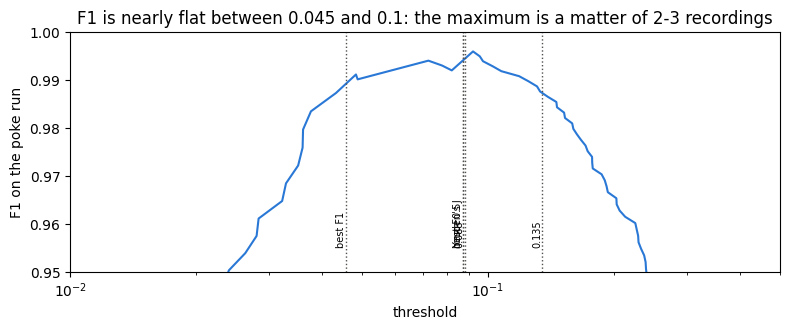

In [7]:
s, m = poke[SCORE].to_numpy(), poke["moving"].to_numpy()
print("highest still scores:  ", np.round(np.sort(s[~m])[-6:], 3))
print("lowest moving scores:  ", np.round(np.sort(s[m])[:8], 3))

recall, precision, f1, thresholds = calibration.precision_recall_curve(s, m)
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(thresholds, f1, color="#2a78d6", lw=1.5)
for name, th in THRESHOLDS.items():
    ax.axvline(th, ls=":", lw=1, color="#52514e")
    ax.text(th, 0.955, name.split(" (")[0].replace(" on the poke run", ""), rotation=90, fontsize=7, va="bottom", ha="right")
ax.set(xscale="log", xlim=(0.01, 0.5), ylim=(0.95, 1.0), xlabel="threshold", ylabel="F1 on the poke run",
       title="F1 is nearly flat between 0.045 and 0.1: the maximum is a matter of 2-3 recordings")
plt.tight_layout()

In [8]:
def weighted_f1_threshold(scores, moving, still_weight):
    # best F1 with each still label counted still_weight times (the highest of equal ones, as best_f1_threshold())
    best = (-1, None)
    for th in np.unique(scores):
        tp = (scores[moving] >= th).sum()
        fp = (scores[~moving] >= th).sum() * still_weight
        fn = (scores[moving] < th).sum()
        f = 2 * tp / (2 * tp + fp + fn)
        if f >= best[0]:
            best = (f, th)
    return best[1]

share = len(long_run[~long_run["moving"]]) / len(long_run[long_run["moving"]])
weights = {w: weighted_f1_threshold(s, m, w) for w in (1, 2, 5, 10, 20)}
print(f"In the long run still recordings outnumber moving ones {share:.0f} to 1; in the poke run's labels moving ones outnumber still 2 to 1.")
pd.DataFrame({"threshold": weights,
              "long run: still called moving": {w: int(((long_run[SCORE] >= th) & ~long_run["moving"]).sum()) for w, th in weights.items()}}
             ).rename_axis("each still label counted ... times")

In the long run still recordings outnumber moving ones 20 to 1; in the poke run's labels moving ones outnumber still 2 to 1.


,threshold,long run: still called moving
each still label counted ... times,,
1,0.048,388
2,0.072,117
5,0.092,65
10,0.092,65
20,0.092,65


Counting each still label even five times, a small fraction of how much more common still recordings are in a run, already moves the best F1 to 0.092, next to where Youden's J puts it (0.087). **The threshold that wrecks the long run is a product of the poke run's label mix, not of the score.**

## 5. Fixes tried

### 5a. Making the score ignore one-pixel changes

Each wrong call in section 3 is narrow: a few of the 64 directions. Three changes to the profile were tried before the vector sum. Each threshold was then recalibrated on the poke run, as a user would, and both F1 and Youden were applied to the long run.

- `median3` / `median5`: a running median over 3 or 5 neighbouring directions, which takes out what is narrower.
- `clip5`: each direction capped at 5 times the profile's median.

In [9]:
E = np.exp(2j * np.pi * np.arange(64) / 64)
vector_sum = lambda p: np.abs((p * E).mean(axis=1))
VARIANTS = {"current": vector_sum(profiles),
            "median3": vector_sum(median_filter(profiles, size=(1, 3), mode="wrap")),
            "median5": vector_sum(median_filter(profiles, size=(1, 5), mode="wrap")),
            "clip5": vector_sum(np.minimum(profiles, 5 * np.median(profiles, axis=1, keepdims=True)))}
assert np.allclose(VARIANTS["current"], table["own_centre"])   # the profile gives back the app's score

rows = {}
for name, v in VARIANTS.items():
    vp, vl = v[poke_rows], v[long_rows]
    for rule, choose in (("F1", lambda a, b: best_f_threshold(a, b, 1.0)), ("F0.5", calibration.best_f05_threshold),
                         ("Youden", calibration.best_threshold)):
        th = choose(vp, poke["moving"])
        rows[(name, rule)] = {"poke AP": calibration.average_precision(vp, poke["moving"]),
                              "poke wrong": int(((vp >= th) != poke["moving"].to_numpy()).sum()),
                              **judged(long_run, vl, th)}
pd.DataFrame(rows).T

poke AP poke wrong threshold still called moving moving called still deaths exact deaths late mean death error (recordings) worst (recordings)
current F1         1.0          3     0.046                 461                   0      14 / 59          45                        92.898                262
        F0.5       1.0          4     0.087                  74                   1      49 / 59          10                         5.881                149
        Youden     1.0          4     0.087                  74                   1      49 / 59          10                         5.881                149
median3 F1       0.999          3     0.049                 337                   0      16 / 59          43                        86.051                269
        F0.5     0.999          5     0.085                  63                   0      50 / 59           9                         5.864                149
        Youden   0.999          3     0.049                 337                   0      16 / 59          43                        86.051                269
median5 F1       0.999          2      0.04                 642                   0       9 / 59          50                       145.678                269
        F0.5     0.999          2      0.04                 642                   0       9 / 59          50                       145.678                269
        Youden   0.999          2      0.04                 642                   0       9 / 59          50                       145.678                269
clip5   F1         1.0          2     0.062                 159                   0      30 / 59          29                        32.254                235
        F0.5       1.0          2     0.062                 159                   0      30 / 59          29                        32.254                235
        Youden     1.0          2     0.062                 159                   0      30 / 59          29                        32.254                235

**None of them helps once recalibrated.** On the poke run each one's threshold comes out lower (0.04–0.06), and the long run ends up no better than with the current score at Youden's threshold or F0.5, or worse. The one near-tie is `median3` at F0.5: 63 still recordings called moving against 74, with the same death error. The score is not where the fix lies.

### 5b. Making the death rule ignore an isolated call

A live run already stops scoring a mite once it has been still for `death_minutes` (200 min, 20 recordings here). After that, a late call can no longer revive it. A second option is to count a call of moving towards the last movement only when another call of moving came within the 3 recordings before it. Each rule is applied to the calls and to the labels alike, so the error below comes from the calls alone.

In [10]:
def live_rule(calls, window=20):
    # as a live run: a mite still for `window` recordings is dead and no longer scored
    last = -1
    for i, called in enumerate(calls):
        if i - last > window:
            break
        if called:
            last = i
    return last + 1


def not_isolated(calls, gap=3):
    # the last movement is the last call of moving with another one at most `gap` recordings before it
    at = np.flatnonzero(calls)
    kept = [i for n, i in enumerate(at) if n > 0 and i - at[n - 1] <= gap]
    return max(kept) + 1 if kept else (at[0] + 1 if len(at) else 0)


rows = {}
for name, th in THRESHOLDS.items():
    for rule_name, rule in (("as now (folder)", death_after), ("live: dead after 200 min", live_rule),
                            ("isolated calls ignored", not_isolated)):
        off = death_offsets(long_run, long_run[SCORE], th, rule)
        rows[(name, rule_name)] = {"deaths exact": f"{(off == 0).sum()} / {len(off)}",
                                   "mean error (recordings)": float(np.abs(off).mean()), "worst": int(np.abs(off).max())}
pd.DataFrame(rows).T

deaths exact mean error (recordings) worst
best F1 on the poke run                      as now (folder)               14 / 59                  92.898   262
                                             live: dead after 200 min      34 / 59                   7.661   178
                                             isolated calls ignored        20 / 59                    39.0   237
best F0.5 on the poke run (in use)           as now (folder)               49 / 59                   5.881   149
                                             live: dead after 200 min      53 / 59                   1.593    52
                                             isolated calls ignored        53 / 59                   0.424    17
Youden's J on the poke run                   as now (folder)               49 / 59                   5.881   149
                                             live: dead after 200 min      53 / 59                   1.593    52
                                             isolated calls ignored        53 / 59                   0.424    17
0.088 (smallest death error on the poke run) as now (folder)               49 / 59                   5.881   149
                                             live: dead after 200 min      53 / 59                   1.593    52
                                             isolated calls ignored        53 / 59                   0.424    17
0.135 (the long run's own)                   as now (folder)               57 / 59                   0.847    46
                                             live: dead after 200 min      58 / 59                   0.068     4
                                             isolated calls ignored        59 / 59                     0.0     0

The death rule absorbs most of the damage at Youden's threshold. The live rule cuts the mean error from about 6 recordings to about 1.6, and ignoring isolated calls cuts it to about 0.4. At the best-F1 threshold neither rule is enough, because the wrong calls there come in runs, not one by one. One caveat: judged against the long run's labels with the plain rule, both rules give deaths that are far off. The labels themselves have gaps of more than 20 recordings between movements, so under these rules the labels' own deaths come early. That is a separate question: whether 200 min is long enough for these mites.

## 6. How steady each choice of threshold is

The poke run's 14 mites resampled with replacement 200 times; each criterion picks its threshold on each resample.

In [11]:
rng = np.random.default_rng(0)
by_mite = {mite: part for mite, part in poke.groupby("mite")}
CRITERIA = {"F1": lambda a, b: best_f_threshold(a, b, 1.0), "F0.5": calibration.best_f05_threshold,
            "Youden's J": calibration.best_threshold}
picked = {name: [] for name in CRITERIA}
for _ in range(200):
    sample = pd.concat([by_mite[m] for m in rng.choice(list(by_mite), len(by_mite))])
    if sample["moving"].all() or not sample["moving"].any():
        continue
    for name, choose in CRITERIA.items():
        picked[name].append(choose(sample[SCORE], sample["moving"]))
pd.DataFrame({name: np.percentile(values, [5, 25, 50, 75, 95]) for name, values in picked.items()},
             index=["5%", "25%", "median", "75%", "95%"]).T

,5%,25%,median,75%,95%
F1,0.042,0.046,0.055,0.060,0.089
F0.5,0.043,0.055,0.087,0.087,0.090
Youden's J,0.043,0.046,0.060,0.087,0.090


F0.5 sits at 0.087–0.09 in more than half of the resamples (median 0.087), where F1's median is 0.055 and Youden's J's 0.060. All three can drop to about 0.043 on an unlucky draw. 22 labelled recordings from the lively first hours cannot pin the threshold down, whatever the criterion; labelling the dead mites' recordings would.

## Findings

**The shake is not what degrades the long run. The threshold is.**

- **Stabilization works on this run.** The plate moves up to 0.24 px within a recording from about 20 h on. Unstabilized, that calls still mites moving. With the app's per-mite centre stabilization the wrong calls are not more common in shaky recordings: they sit in the calmest ones. The plate-wide centre and ECC shifts do no better (section 2).
- **Best F1 on the poke run puts the threshold at about 0.046–0.049.** That is half of Youden's J (0.087–0.092) and of the earlier death-error choice (0.088). Applied to the long run it calls about 460 still recordings moving, and deaths come about 90 recordings (15 h) late on average (section 1). The poke run cannot see this. Its labels are two-thirds moving, from the lively first 3.5 h, with no dead mites, so F1 gains from going lower, and only 2–3 recordings decide where its maximum falls (section 4).
- **Even at 0.088 a few calls revive dead mites.** 13 still recordings after a mite's last movement are called moving. In each one a single pixel or two on the outline changes: a slow sub-pixel step, a one-frame spike or a flicker. In a 10-frame recording that reaches a score of 0.09–0.14 (section 3).
- **Changing the score does not fix it.** Medians and caps across the outline's directions only move the recalibrated threshold down with them (section 5a).

**What changed after this notebook:** the calibration report now suggests the threshold with the best **F0.5** (`calibration.best_f05_threshold()`), which counts a still recording called moving four times as much as a moving one called still. On the poke run it gives the same threshold as Youden's J here, and it holds there in more of the resamples of the mites than Youden's J or F1 (section 6).

**Suggested fixes, in order:**

1. **Do not calibrate with plain best F1 on moving-heavy labels** (done: F0.5). Either go back to Youden's J, which balances the classes and gives 0.09 here, or weight the still labels in F1 by how common still recordings are in a run. A weight of 5 already gives 0.092 (section 4). This is the change that removes the "massive" degradation: about 460 → about 70 wrong calls, mean death error about 93 → about 6 recordings.
2. **Label still recordings of dead mites in the calibration run.** The poke run's labels stop at 3.5 h. Labelling its later recordings, up to where the live run dropped each dead mite, gives the still tail that the threshold has to clear. Without those labels no threshold choice can see the tail.
3. **Optionally, let an isolated call not revive a mite** (section 5b). This cuts the remaining death error at 0.09 from about 6 to about 0.4 recordings. A live run already gets most of that benefit from `death_minutes`.

**Limits.** The long run records 10 frames, not 90. On the poke run, cutting recordings to 10 frames leaves the still mites' scores about where they were, but the one-pixel events of section 3 weigh more in 10 frames than in 90. A 3 s / 30 fps run that shakes, with dead mites labelled, would settle how much of this carries over to the current recordings. The long run's labels are close to the score at 0.135, so they cannot judge thresholds above 0.135. The pixels in section 3 are the label-free evidence.